
# Viés e Variância em Machine Learning

## Objetivo

A ideia deste notebook é entender **viés** e **variância** de forma visual

Vamos usar uma situação artificial em que conhecemos a função verdadeira que gerou os dados. Isso nos permite fazer uma pergunta que, no mundo real, normalmente não conseguimos responder diretamente:

> **Se eu repetisse a coleta de dados várias vezes e treinasse o mesmo modelo novamente, o que mudaria?**

Neste notebook:

- analisamos diretamente a **variação das previsões dos modelos**;
- vemos um exemplo com relação **linear**;
- depois vemos um exemplo com relação **não linear**.

### A ideia central é entender os dois conceitos de maneira prática e visual:

- **Viés:** as previsões ficam, em média, longe da relação verdadeira?
- **Variância:** as previsões mudam muito quando mudamos a amostra de treinamento?


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

np.random.seed(42)



## 1. Imagine que conhecemos a função verdadeira

Em dados reais, não conhecemos a função verdadeira \(f(x)\).

Aqui vamos criar um mundo artificial em que sabemos exatamente qual é essa função. Assim, conseguimos comparar o que o modelo aprende com a **realidade**.

Começaremos com uma relação linear:

$ f(x) = 2 + 1.5x $

Os dados observados terão também um erro aleatório ($\epsilon$), fazendo com que os pontos não caiam exatamente sobre a linha verdadeira:

$ y = f(x) + \epsilon $

O erro faz com que os pontos não caiam exatamente sobre a linha verdadeira.


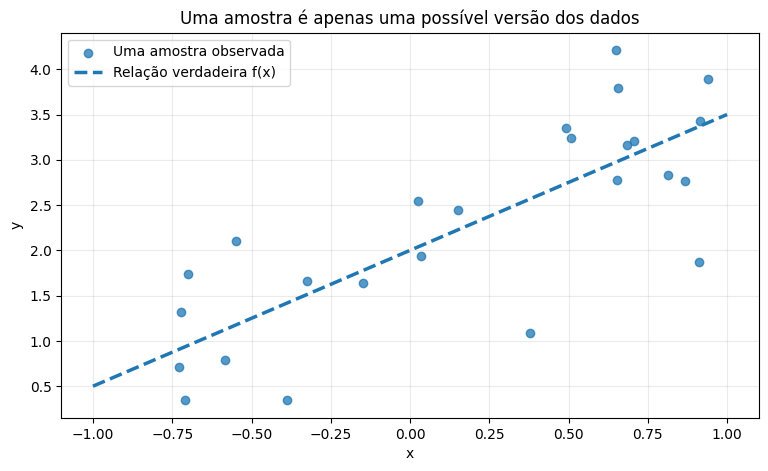

In [ ]:

def f_linear(x):
    return 2 + 1.5 * x

rng = np.random.default_rng(10)

n = 25
sigma = 0.8

X = rng.uniform(-1, 1, n)
y = f_linear(X) + rng.normal(0, sigma, n)

x_grid = np.linspace(-1, 1, 200)

plt.figure(figsize=(9, 5))
plt.scatter(X, y, alpha=0.75, label="Uma amostra observada")
plt.plot(x_grid, f_linear(x_grid), linestyle="--", linewidth=2.5,
         label="Relação verdadeira f(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Uma amostra é apenas uma possível versão dos dados")
plt.legend()
plt.grid(alpha=0.25)
plt.show()



## 2. Vamos repetir a coleta de dados

Como nós mesmos criamos a população artificial, podemos simplesmente:

1. coletar uma nova amostra;
2. treinar o modelo;
3. descartar essa amostra;
4. coletar outra amostra da mesma população;
5. treinar novamente.

Cada conjunto abaixo representa uma **nova coleta independente**, feita sob as mesmas condições.

Isso representa a pergunta:

> **O que aconteceria com o modelo se tivéssemos recebido outra amostra da mesma população?**


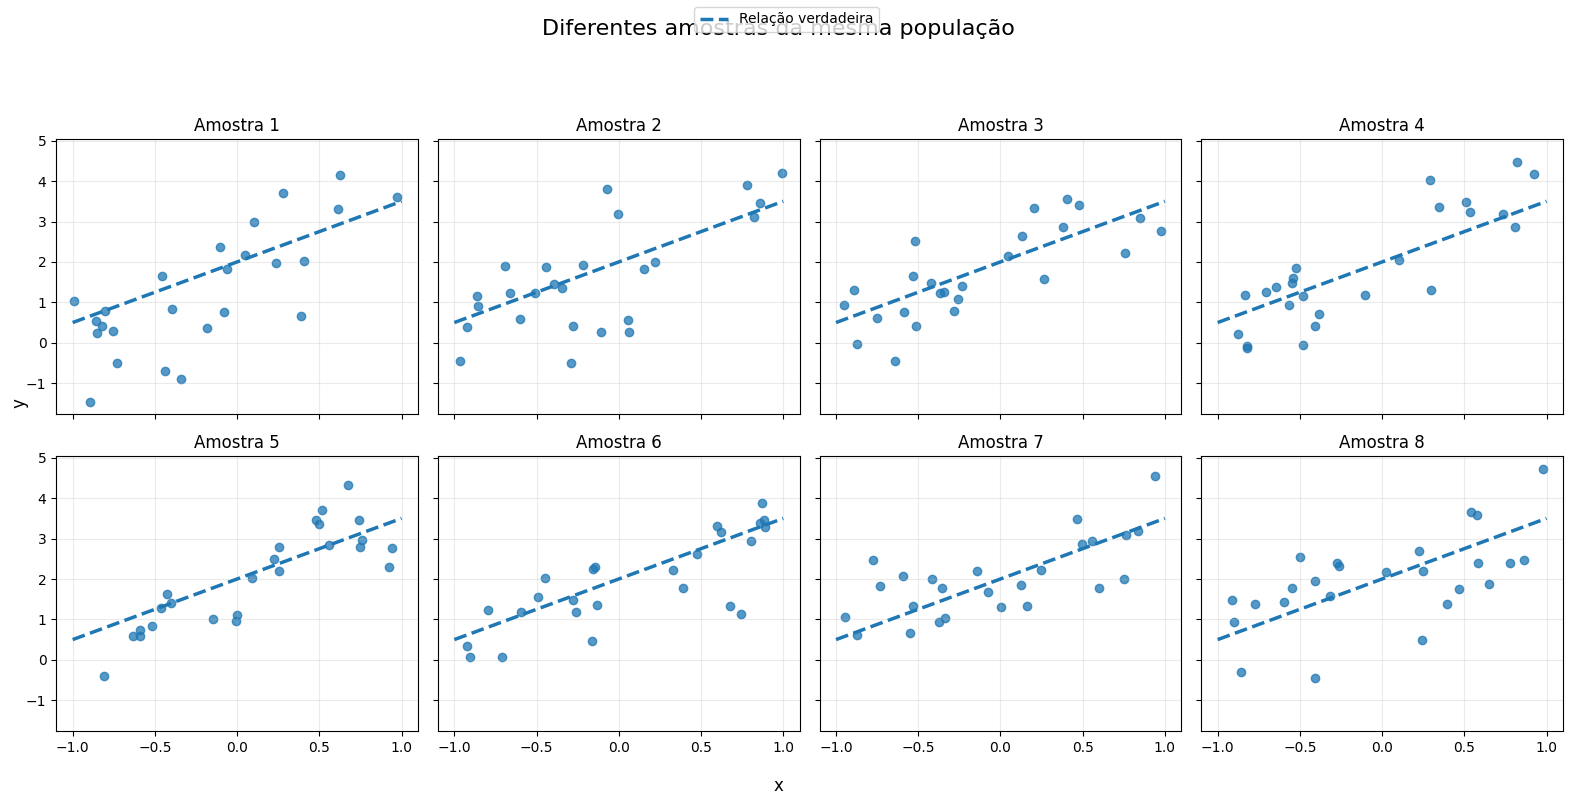

In [ ]:
rng = np.random.default_rng(20)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i in range(8):
    X_i = rng.uniform(-1, 1, n)
    y_i = f_linear(X_i) + rng.normal(0, sigma, n)

    axes[i].scatter(X_i, y_i, alpha=0.75)
    axes[i].plot(
        x_grid,
        f_linear(x_grid),
        linestyle="--",
        linewidth=2.5,
        label="Relação verdadeira"
    )

    axes[i].set_title(f"Amostra {i + 1}")
    axes[i].grid(alpha=0.25)

# Rótulos gerais
fig.supxlabel("x")
fig.supylabel("y")

# Uma legenda única para a figura inteira
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=1)

fig.suptitle("Diferentes amostras da mesma população", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


## 3. Treinando o mesmo tipo de modelo em várias amostras

Agora repetimos a coleta muitas vezes.

Em cada repetição:

- geramos novos dados;
- treinamos um modelo;
- pedimos ao modelo que faça previsões nos mesmos valores de \(x\).

Dessa forma, podemos responder algo diretamente relacionado ao objetivo do modelo:

> **Como as previsões mudam de uma amostra para outra?**

Vamos usar regressão polinomial apenas como um **controle de flexibilidade**:

- grau 1 → uma reta, pouco flexível;
- grau 5 → uma curva muito mais flexível.


In [ ]:

def criar_modelo(grau):
    return make_pipeline(
        PolynomialFeatures(degree=grau, include_bias=False),
        LinearRegression()
    )

def repetir_experimento(funcao_real, grau, n_repeticoes=300,
                        n_pontos=25, sigma=2, seed=123):
    rng = np.random.default_rng(seed)
    x_grid = np.linspace(-1, 1, 200)
    previsoes = []

    for _ in range(n_repeticoes):
        X = rng.uniform(-1, 1, n_pontos)
        y = funcao_real(X) + rng.normal(0, sigma, n_pontos)

        modelo = criar_modelo(grau)
        modelo.fit(X.reshape(-1, 1), y)

        y_pred = modelo.predict(x_grid.reshape(-1, 1))
        previsoes.append(y_pred)

    return x_grid, np.array(previsoes)


In [ ]:

x_grid, pred_linear_g1 = repetir_experimento(
    f_linear, grau=1, sigma=sigma
)

_, pred_linear_g5 = repetir_experimento(
    f_linear, grau=5, sigma=sigma
)

print("Formato da matriz de previsões:", pred_linear_g1.shape)
print("Cada linha = um modelo treinado em uma nova amostra.")
print("Cada coluna = a previsão desses modelos em um mesmo valor de x.")


Formato da matriz de previsões: (300, 200)
Cada linha = um modelo treinado em uma nova amostra.
Cada coluna = a previsão desses modelos em um mesmo valor de x.



## 4. Observando a variância: quanto o modelo muda quando a amostra muda?

Nos gráficos seguintes, cada linha fina corresponde ao modelo obtido a partir de uma nova amostra.

Se as linhas ficam muito próximas umas das outras, o método é **estável** diante de mudanças nos dados.

Se as linhas se espalham muito, pequenas mudanças na amostra produzem modelos bastante diferentes.

Esse espalhamento é a ideia de **variância**.


In [ ]:

def mostrar_modelos(funcao_real, x_grid, previsoes, titulo, n_linhas=30):
    plt.figure(figsize=(9, 5))

    # vários modelos treinados em várias amostras
    plt.plot(x_grid, previsoes[:n_linhas].T, alpha=0.14)

    # relação verdadeira
    plt.plot(x_grid, funcao_real(x_grid), linestyle="--", linewidth=3,
             label="Relação verdadeira")

    # média das previsões
    plt.plot(x_grid, previsoes.mean(axis=0), linewidth=3,
             label="Previsão média")

    plt.xlabel("x")
    plt.ylabel("Previsão")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


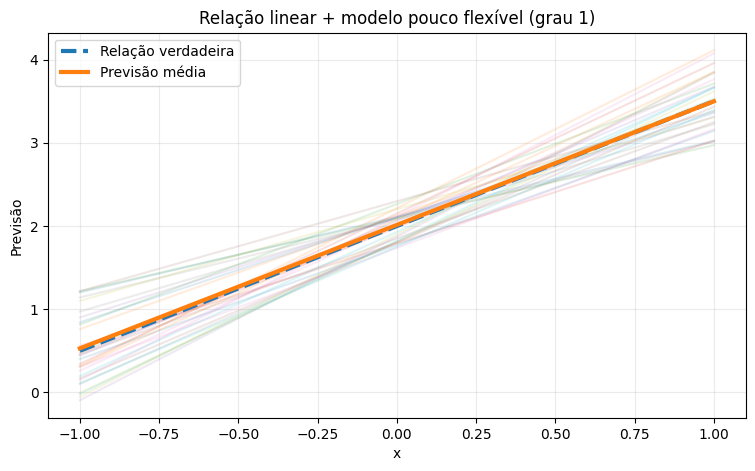

In [ ]:

mostrar_modelos(
    f_linear,
    x_grid,
    pred_linear_g1,
    "Relação linear + modelo pouco flexível (grau 1)"
)


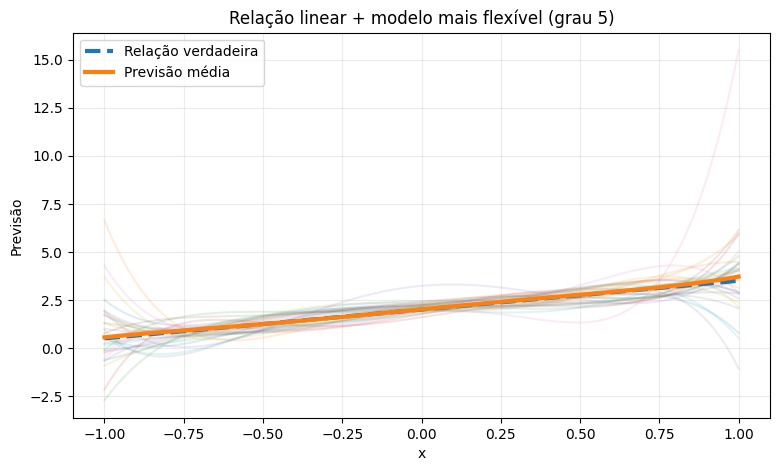

In [ ]:

mostrar_modelos(
    f_linear,
    x_grid,
    pred_linear_g5,
    "Relação linear + modelo mais flexível (grau 5)"
)



### Observamos que:

No problema simulado, a realidade é linear, de forma que:

- O modelo de grau 1 tem a forma adequada para o problema. Quando a amostra muda, ele tende a mudar relativamente pouco.

- O modelo de grau 5 possui liberdade para criar curvaturas que **não existem na função verdadeira**. Como consequência, ele pode reagir ao ruído específico de cada amostra.

Isso aparece como um conjunto de curvas mais espalhadas, de forma que **maior flexibilidade pode produzir maior variância.**



## 5. Viés e variância olhando uma única entrada $x_0$

Vamos fixar um valor, por exemplo:

$x_0 = 0.7$

Treinamos centenas de modelos em diferentes amostras e perguntamos a todos:

> **Qual seria sua previsão em $x_0$?**

Teremos então centenas de respostas para exatamente o mesmo $x_0$

- A distância entre a **média das previsões** e o valor verdadeiro representa o **viés** naquele ponto.
- O espalhamento das previsões representa a **variância** naquele ponto.


In [ ]:

def analisar_em_um_ponto(funcao_real, x_grid, previsoes, x0, titulo):
    indice = np.argmin(np.abs(x_grid - x0))
    x_usado = x_grid[indice]

    preds_x0 = previsoes[:, indice]
    valor_real = funcao_real(x_usado)
    media_pred = preds_x0.mean()

    vies = media_pred - valor_real
    variancia = preds_x0.var()

    plt.figure(figsize=(9, 5))
    plt.hist(preds_x0, bins=25, alpha=0.7)
    plt.axvline(valor_real, linestyle="--", linewidth=3,
                label=f"Valor verdadeiro = {valor_real:.2f}")
    plt.axvline(media_pred, linewidth=3,
                label=f"Média das previsões = {media_pred:.2f}")
    plt.xlabel(f"Previsão em x = {x_usado:.2f}")
    plt.ylabel("Quantidade de modelos")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    print(f"Viés nesse ponto: {vies:.4f}")
    print(f"Variância nesse ponto: {variancia:.4f}")


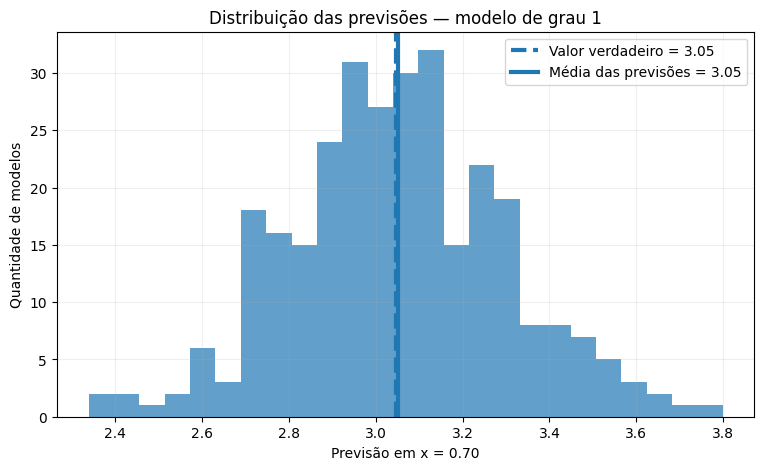

Viés nesse ponto: 0.0032
Variância nesse ponto: 0.0614


In [ ]:

analisar_em_um_ponto(
    f_linear,
    x_grid,
    pred_linear_g1,
    x0=0.7,
    titulo="Distribuição das previsões — modelo de grau 1"
)


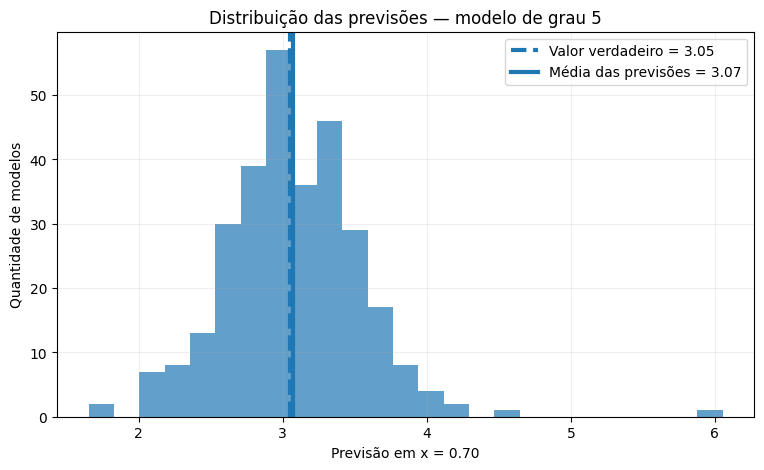

Viés nesse ponto: 0.0232
Variância nesse ponto: 0.2231


In [ ]:

analisar_em_um_ponto(
    f_linear,
    x_grid,
    pred_linear_g5,
    x0=0.7,
    titulo="Distribuição das previsões — modelo de grau 5"
)



## 6. Problema realmente não linear

Até aqui, a função verdadeira era uma reta. Isso favorecia naturalmente o modelo linear.

Agora vamos mudar a realidade para:

$ f(x) = 1 + 2x - 2.5x^2 $

A relação entre \(x\) e \(y\) é curva.

Vamos comparar três níveis de flexibilidade:

- **grau 1:** pouco flexível;
- **grau 2:** flexibilidade compatível com a relação verdadeira;
- **grau 5:** mais flexível do que o necessário.


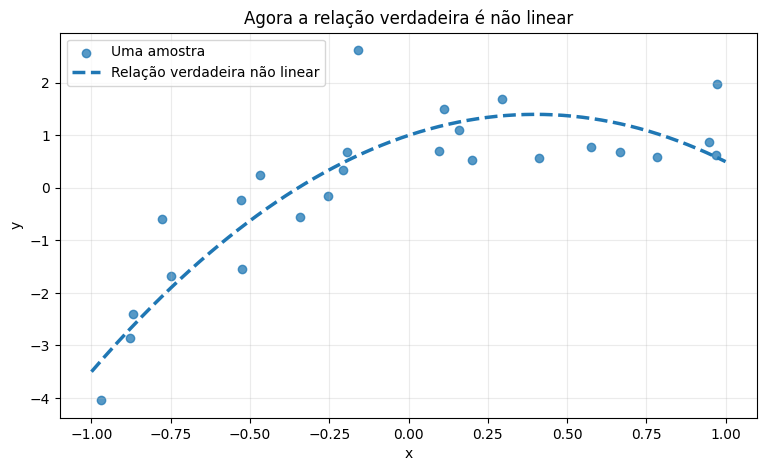

In [ ]:

def f_nao_linear(x):
    return 1 + 2*x - 2.5*(x**2)

rng = np.random.default_rng(50)

X = rng.uniform(-1, 1, 25)
y = f_nao_linear(X) + rng.normal(0, 0.7, 25)

plt.figure(figsize=(9, 5))
plt.scatter(X, y, alpha=0.75, label="Uma amostra")
plt.plot(x_grid, f_nao_linear(x_grid), linestyle="--", linewidth=2.5,
         label="Relação verdadeira não linear")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Agora a relação verdadeira é não linear")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [ ]:

sigma_nl = 0.7

x_grid, pred_nl_g1 = repetir_experimento(
    f_nao_linear, grau=1, sigma=sigma_nl
)

_, pred_nl_g2 = repetir_experimento(
    f_nao_linear, grau=2, sigma=sigma_nl
)

_, pred_nl_g5 = repetir_experimento(
    f_nao_linear, grau=5, sigma=sigma_nl
)



### Modelo pouco flexível: grau 1

Observe duas coisas separadamente:

1. as retas obtidas em diferentes amostras não precisam variar tanto;
2. porém, a **previsão média** continua distante da curva verdadeira.

Isso é um caso típico de **alto viés**: o formato imposto ao modelo é simples demais para representar a relação verdadeira.


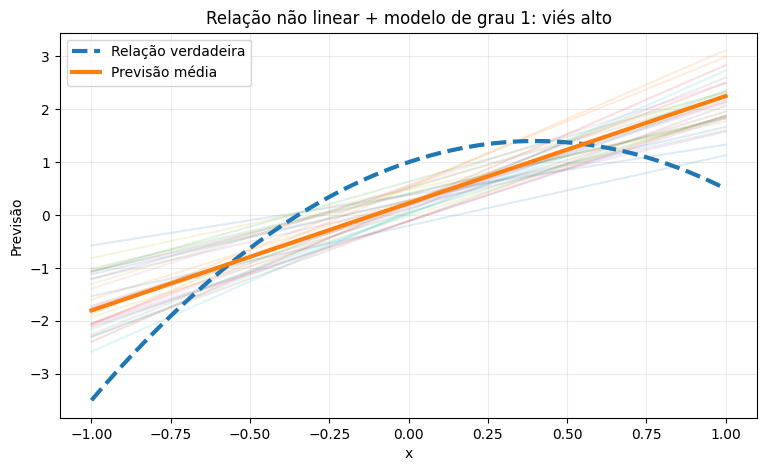

In [ ]:

mostrar_modelos(
    f_nao_linear,
    x_grid,
    pred_nl_g1,
    "Relação não linear + modelo de grau 1: viés alto"
)



### Flexibilidade adequada: grau 2

Agora o modelo consegue representar a curvatura existente na relação verdadeira.

A tendência é obter:

- viés menor;
- sem tornar o modelo excessivamente instável.


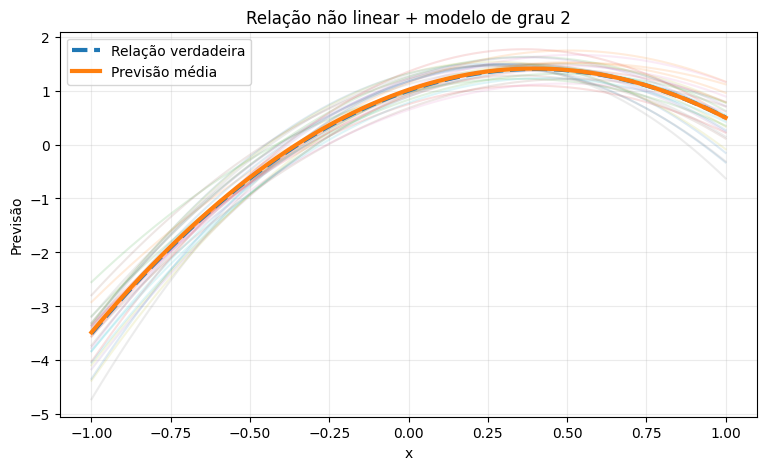

In [ ]:

mostrar_modelos(
    f_nao_linear,
    x_grid,
    pred_nl_g2,
    "Relação não linear + modelo de grau 2"
)



### Modelo muito flexível: grau 5

O modelo também consegue representar a curvatura verdadeira, mas possui liberdade adicional.

Parte dessa liberdade pode ser usada para perseguir o ruído de cada amostra.

Resultado:

> o viés pode continuar baixo, enquanto a variância aumenta.


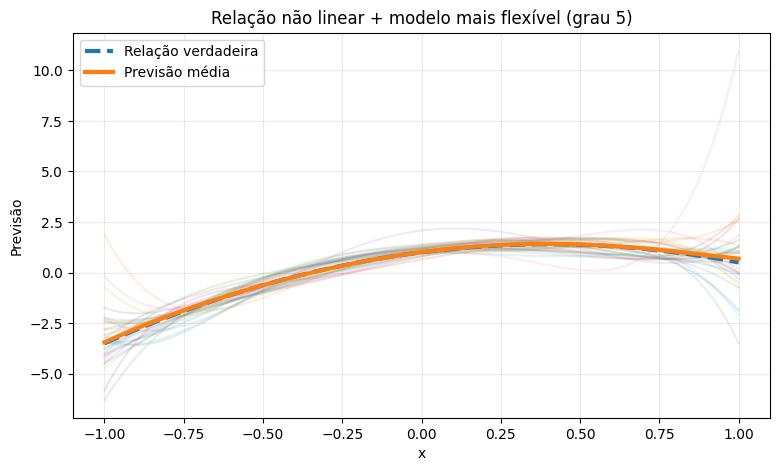

In [ ]:

mostrar_modelos(
    f_nao_linear,
    x_grid,
    pred_nl_g5,
    "Relação não linear + modelo mais flexível (grau 5)"
)



## 7. Colocando números nas ideias

Até agora, usamos os gráficos.

Agora podemos resumir numericamente o que vimos.

Para cada valor de \(x\):

1. calculamos a média das previsões de todos os modelos;
2. comparamos essa média com \(f(x)\) → **viés**;
3. medimos o quanto as previsões dos diferentes modelos se espalham → **variância**.

Como o viés pode ser positivo em alguns pontos e negativo em outros, usamos o **viés ao quadrado médio** para obter um único número de resumo.


In [ ]:

def resumir_vies_variancia(nome, funcao_real, x_grid, previsoes):
    realidade = funcao_real(x_grid)
    media_pred = previsoes.mean(axis=0)

    vies_por_x = media_pred - realidade
    vies2_medio = np.mean(vies_por_x ** 2)

    variancia_por_x = np.var(previsoes, axis=0)
    variancia_media = np.mean(variancia_por_x)

    return {
        "Modelo": nome,
        "Viés² médio": vies2_medio,
        "Variância média": variancia_media
    }

resultados = pd.DataFrame([
    resumir_vies_variancia(
        "Grau 1 — pouco flexível",
        f_nao_linear, x_grid, pred_nl_g1
    ),
    resumir_vies_variancia(
        "Grau 2 — adequado",
        f_nao_linear, x_grid, pred_nl_g2
    ),
    resumir_vies_variancia(
        "Grau 5 — mais flexível",
        f_nao_linear, x_grid, pred_nl_g5
    )
])

resultados.round(4)


,Modelo,Viés² médio,Variância média
0,Grau 1 — pouco flexível,0.5712,0.1098
1,Grau 2 — adequado,0.0002,0.0660
2,Grau 5 — mais flexível,0.0018,0.7258



### Interpretação esperada

Isso resume o **trade-off viés–variância**: aumentar a flexibilidade tende a reduzir o viés, mas pode aumentar a variância.

Queremos encontrar flexibilidade suficiente para capturar a estrutura real dos dados, sem começar a perseguir excessivamente o ruído.



## 8. Comlpemento sobre erro irreduzível

Mesmo que conhecêssemos perfeitamente \(f(x)\), ainda teríamos:

$ y = f(x) + \epsilon $

O termo $\epsilon$ representa variação aleatória que não pode ser prevista a partir de $x$.

Portanto, há três ideias diferentes:

- **Viés:** erro sistemático causado pela forma como o modelo aproxima a realidade;
- **Variância:** sensibilidade do modelo à amostra de treinamento;
- **Erro irreduzível:** ruído presente no próprio processo que gera os dados.

A decomposição clássica do erro pode ser estudada **depois** dessas ideias visuais. Ela não é necessária para entender a intuição inicial.



# Algumas questões para reflexão

1. No exemplo não linear, por que o modelo de grau 1 apresenta viés mesmo quando usamos muitas amostras?
2. Por que coletar uma nova amostra pode alterar mais um modelo muito flexível?
3. Aumentar o número de observações de treinamento deve afetar mais diretamente o viés ou a variância?
4. O que deve acontecer com os modelos quando aumentamos muito o desvio padrão do ruído?
5. Se a relação verdadeira for uma reta, há alguma vantagem em usar um modelo extremamente flexível?
